# Descriptive stats for all columns

In [1]:
import matplotlib as plt
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

### Load the Data

In [2]:
RAW = "../data/raw"
df = pd.read_csv(f"{RAW}/diabetic_data.csv")
variables = pd.read_csv(f"{RAW}/variables.csv")

df.shape

C:\Users\cameron.letendre\AppData\Local\Temp\ipykernel_38644\3568291170.py:2: DtypeWarning: Columns (8: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"{RAW}/diabetic_data.csv")


(101766, 48)

Output Directory

In [3]:
out = Path("../reports/figures")
out.mkdir(parents=True, exist_ok=True)

#### View of Numerical data

In [4]:
df.describe()

,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


#### View of Categorical data

In [5]:
for col in df.select_dtypes("object"):
    if col in df.columns:
        print(col)

race
gender
age
weight
payer_code
medical_specialty
diag_1
diag_2
diag_3
max_glu_serum
A1Cresult
metformin
repaglinide
nateglinide
chlorpropamide
glimepiride
acetohexamide
glipizide
glyburide
tolbutamide
pioglitazone
rosiglitazone
acarbose
miglitol
troglitazone
tolazamide
examide
citoglipton
insulin
glyburide-metformin
glipizide-metformin
glimepiride-pioglitazone
metformin-rosiglitazone
metformin-pioglitazone
change
diabetesMed
readmitted


C:\Users\cameron.letendre\AppData\Local\Temp\ipykernel_38644\3997384342.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object"):


Unique Value Counts

In [6]:
for col in df.select_dtypes("object"):
    print(f"{df[col].value_counts(dropna=False)}\n")

race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

weight
NaN          98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64

payer_code
NaN    40256
MC     32439
HM      6274
SP      5007
BC      4655
MD      3532
CP      2533
UN      2448
CM      1937
OG      1033
PO       592
DM       549
CH       146
WC       135
OT        95
MP        79
SI        55
FR         1
Name: count, dtype: int64

me

C:\Users\cameron.letendre\AppData\Local\Temp\ipykernel_38644\4195830634.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object"):


Number of Categorical vs Numerical Columns

In [7]:
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns

print(f"Numeric columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")
print(f"Total: {df.shape[1]}")

Numeric columns: 11
Categorical columns: 37
Total: 48


### Amount of patients who repeat encounter

In [8]:
visits = df["patient_nbr"].value_counts()

print(f"Patients: {len(visits):,}")
print(f"Patients with 2+ encounters: {(visits > 1).sum():,} ({(visits > 1).mean():.1%})")
print(f"Encounters from repeat patients: {visits[visits > 1].sum():,} ({visits[visits > 1].sum() / len(df):.1%})")


KeyError: 'patient_nbr'

## Three-Class Readmitted Split

In [ ]:
# Count each class in a meaningful order (not sorted by size)
order = ["<30", ">30", "NO"]
counts = df["readmitted"].value_counts().reindex(order)
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Within 30 days", "After 30 days", "Not readmitted"], counts,
              width=0.5, color="#2a78d6")

# Count + percentage on top of each bar
for bar, n, p in zip(bars, counts, pct):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({p:.1f}%)",
            ha="center", va="bottom", fontsize=9)

ax.set_title("Readmission outcome (readmitted)", loc="left")
ax.set_ylabel("Encounters")
ax.yaxis.set_major_formatter(lambda y, _: f"{y/1000:.0f}K" if y else "0")
ax.set_ylim(0, counts.max() * 1.18)       
ax.grid(axis="y", color="#e5e5e2", linewidth=1)
ax.set_axisbelow(True)                   
ax.tick_params(left=False)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

fig.savefig(out / "readmitted_split.png", dpi=200, bbox_inches="tight")
plt.show()


## Column Missing-ness Number

In [ ]:
missing_num = []

for col in df.columns:
    n_nan = df[col].isna().sum()
    if n_nan:
        missing_num.append([col, n_nan])
        print(f"{col}: {n_nan} NaN,({n_nan / len(df):.1%})")


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

missing_num = sorted(missing_num, key=lambda x: x[1], reverse=True)

cols = [col for col, _ in missing_num]
pct = [num / len(df) * 100 for _, num in missing_num]
bars = ax.bar(cols, pct, width=0.5, color="#2a78d6")
ax.bar_label(bars, labels=[f"{p:.1f}%" for p in pct], fontsize=12)

ax.set_title("% of missing values by column", loc="left")
ax.set_ylabel("Percentage")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", color="#e5e5e2", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(left=False)

plt.show()


Columns over 50% missing values

In [ ]:
def read_info(col):
    print(f"{df[col].dropna().sample(3)}")    
    print(f"{"-"*20}")

for col in cols:
    read_info(col)

## Drug Status column plots against Readmission

Text(0, 0.5, 'Count')

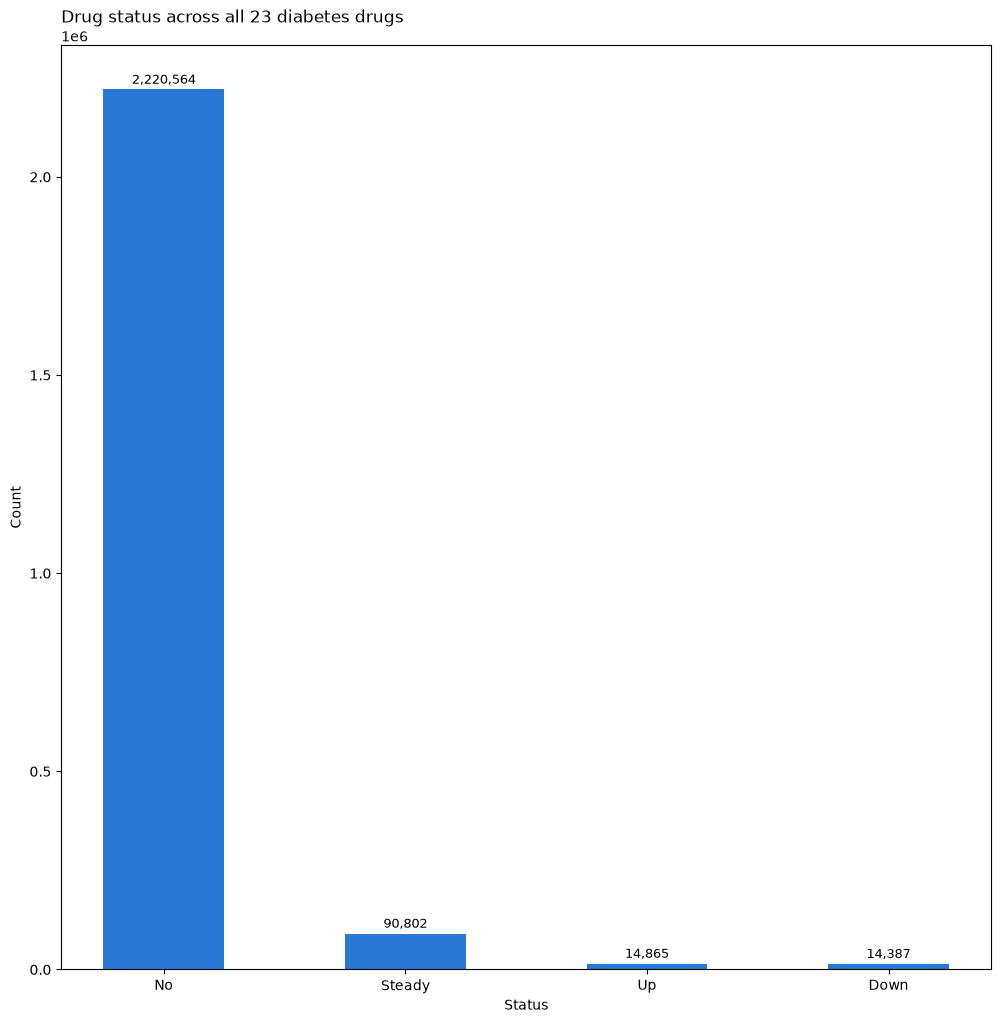

In [ ]:
drug_predictors = ["metformin",
"repaglinide",
"nateglinide",
"chlorpropamide",
"glimepiride",
"acetohexamide",
"glipizide",
"glyburide",
"tolbutamide",
"pioglitazone",
"rosiglitazone",
"acarbose",
"miglitol",
"troglitazone",
"tolazamide",
"examide",
"citoglipton",
"insulin",
"glyburide-metformin",
"glipizide-metformin",
"glimepiride-pioglitazone",
"metformin-rosiglitazone",
"metformin-pioglitazone",
]

status_totals  = df[drug_predictors].melt()["value"].value_counts()

fig, ax = plt.subplots(figsize=(12, 12))

bars = ax.bar(status_totals.index, status_totals, width=0.5, color="#2a78d6")
ax.bar_label(bars, labels=[f"{n:,}" for n in status_totals], fontsize=9, padding=2)

ax.set_title("Drug status across all 23 diabetes drugs", loc="left")
ax.set_xlabel("Status")                        # x-axis label
ax.set_ylabel("Count")                         # y-axis label



Which values each drug contains

In [ ]:
n_status = df[drug_predictors].nunique()

print("Number of drugs cols that don't have all 4 statuses")
print(f"{len(n_status[n_status < 4])}/{len(drug_predictors)}\n")

for drug in n_status[n_status < 4].index:
    print(drug, sorted(df[drug].unique()))



Number of drugs cols that don't have all 4 statuses
10/23

acetohexamide ['No', 'Steady']
tolbutamide ['No', 'Steady']
troglitazone ['No', 'Steady']
tolazamide ['No', 'Steady', 'Up']
examide ['No']
citoglipton ['No']
glipizide-metformin ['No', 'Steady']
glimepiride-pioglitazone ['No', 'Steady']
metformin-rosiglitazone ['No', 'Steady']
metformin-pioglitazone ['No', 'Steady']


In [ ]:
first_visit = df.drop_duplicates("patient_nbr")
multi = (first_visit[drug_predictors] != "No").sum(axis=1) >= 2
print(f"Patients on 2+ drugs at first encounter: {multi.sum():,} ({multi.mean():.1%})")


KeyError: Index(['patient_nbr'], dtype='str')

In [ ]:
drugs_per_row = (df[drug_predictors] != "No").sum(axis=1)
order = ["<30", ">30", "NO"]
labels = ["Within 30 days", "After 30 days", "Not readmitted"]
thresholds = [2, 3, 4]

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharey=True)

for ax, k in zip(axes, thresholds):
    sub = df[drugs_per_row >= k]
    counts = sub["readmitted"].value_counts().reindex(order)
    pct = counts / counts.sum() * 100

    bars = ax.bar(labels, pct, width=0.5, color="#2a78d6")
    for bar, n, p in zip(bars, counts, pct):
        ax.text(bar.get_x() + bar.get_width() / 2, p, f"{p:.1f}%\n(n={n:,})",
                ha="center", va="bottom", fontsize=8)

    ax.set_title(f"{k}+ drugs (n={len(sub):,})", loc="left")
    ax.grid(axis="y", color="#e5e5e2", linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(left=False)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("% of encounters")
axes[0].set_ylim(0, 100)
fig.suptitle("Readmission outcome by number of diabetes drugs", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(out / "readmitted_by_drug_count.png", dpi=200, bbox_inches="tight")
plt.show()


### Readmission rate by key Cat Columns

In [ ]:
key_cols = ["age", "race", "gender", "admission_type_id", "diabetesMed", "change", "insulin"]
key_out = Path("../reports/figures/key_cols")
key_out.mkdir(parents=True, exist_ok=True)

In [ ]:
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)

for col in key_cols:
    rate = df.groupby(col)["readmit_30"].mean() * 100

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(rate.index.astype(str), rate, width=0.6, color="#2a78d6")
    ax.bar_label(bars, labels=[f"{p:.1f}%" for p in rate], fontsize=8, padding=2)
    ax.set_title(f"30-day readmission rate by {col}", loc="left")
    ax.set_ylabel("% readmitted within 30 days")
    ax.tick_params(axis="x", rotation=45)

    fig.savefig(out / f"key_cols/{col}.png", dpi=200, bbox_inches="tight")
    plt.show()




## Categorical Summary Table 

In [ ]:
visits = df["patient_nbr"].value_counts()
drugs_per_row = (df[drug_predictors] != "No").sum(axis=1)
readmit_30 = (df["readmitted"] == "<30")

summary = pd.DataFrame([
    ["Encounters",                     f"{len(df):,}"],
    ["Distinct patients",              f"{len(visits):,}"],
    ["Patients with 2+ encounters",    f"{(visits > 1).sum():,} ({(visits > 1).mean():.1%})"],
    ["Columns (numeric / categorical)", f"{df.shape[1]} ({len(num_cols)} / {len(cat_cols)})"],
    ["Columns with >50% missing",      ", ".join(c for c, n in missing_num if n / len(df) > 0.5)],
    ["Readmitted <30 days",            f"{readmit_30.sum():,} ({readmit_30.mean():.1%})"],
    ["Readmitted >30 days",            f"{(df['readmitted'] == '>30').sum():,} ({(df['readmitted'] == '>30').mean():.1%})"],
    ["Not readmitted",                 f"{(df['readmitted'] == 'NO').sum():,} ({(df['readmitted'] == 'NO').mean():.1%})"],
    ["Encounters on 2+ diabetes drugs", f"{(drugs_per_row >= 2).sum():,} ({(drugs_per_row >= 2).mean():.1%})"],
    ["Drugs never prescribed",         ", ".join(n_status[n_status == 1].index)],
], columns=["Metric", "Value"])

summary


In [ ]:
summary.to_csv(out / "eda_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 0.4 * len(summary) + 0.5))
ax.axis("off")
tbl = ax.table(cellText=summary.values, colLabels=summary.columns,
               cellLoc="left", colLoc="left", loc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.4)
tbl.auto_set_column_width([0, 1])
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor("#e5e5e2")
    if r == 0:
        cell.set_text_props(weight="bold")
        cell.set_facecolor("#f2f2f0")
fig.savefig(out / "eda_summary.png", dpi=200, bbox_inches="tight")
plt.show()


## Numeric Columns against target

In [ ]:
visit_cols = ["number_inpatient", "number_emergency", "number_outpatient",]


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, visit_cols):
    data = df[col]                                  # raw column, one value per encounter
    ax.hist(data, bins=range(0, 16), color="#2a78d6", align="left", rwidth=0.8)
    ax.set_title(col.replace("number_", "Prior ") + " visits", loc="left")
    ax.set_xlabel("Visits in prior year")
    ax.set_yscale("log")
    ax.set_xlim(-1, 15)
    ax.grid(axis="y", color="#e5e5e2", linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(left=False)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("Encounters")
fig.tight_layout()
fig.savefig(out / "prior_visits_hist.png", dpi=200, bbox_inches="tight")
plt.show()

Readmission rate for 30< days 

In [ ]:
for col in visit_cols:
    binned = df[col].clip(upper=10) if col.startswith("number_") else pd.qcut(df[col], 5, duplicates="drop")
    print(df.groupby(binned, observed=True)["readmit_30"].agg(rate="mean", n="size").assign(rate=lambda s: (s.rate * 100).round(1)), "\n")


clip(upper=5) caps the values. Any number above 10 becomes 10. Numbers at or below 10 stay as they are. 

a patient with 12 prior inpatient visits is treated as having 10. So then when grouped by that column, you get 11 groups:
0, 1, 2, ..., 10 or more"

This is because few patients have 10+, prior visits so if left as separate groups, each one has a handful of rows and its readmission rate is noise

In [ ]:
situation_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures",
             "num_medications", "number_diagnoses"]
overall = df["readmit_30"].mean() * 100

fig, axes = plt.subplots(5, 1, figsize=(12, 24),
                         sharey=True, layout="constrained")

for ax, col in zip(axes, situation_cols):
    if df[col].nunique() <= 10:
        binned = df[col]                                   # few values: keep as is
    else:
        binned = pd.qcut(df[col], 5, duplicates="drop")    # many values: 5 equal-size bins
    g = df.groupby(binned, observed=True)["readmit_30"].agg(rate="mean", n="size")
    g["rate"] *= 100

    bars = ax.bar(g.index.astype(str), g["rate"], width=0.6, color="#2a78d6")
    ax.bar_label(bars, labels=[f"{r:.1f}" for r in g["rate"]], fontsize=8, padding=2)
    ax.set_title(col, loc="left")
    ax.grid(axis="y", color="#e5e5e2", linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(left=False)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("% readmitted within 30 days")
fig.suptitle("30-day readmission rate by stay characteristics", x=0.01, ha="left")
fig.savefig(out / "readmit_rate_stay_cols.png", dpi=200, bbox_inches="tight")
plt.show()
